# 04 · Weekly Growth and Loss Report

**Goal:** the weekly leadership view. How many players did we gain, how many did we lose, and what happened to player money this week?

Reads `fct_player_week`, `fct_player_week_status` and `ref_week`. Writes `agg_weekly_kpis` and exports `outputs/weekly_kpis.csv` for Power BI.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent
con = sqlite3.connect(ROOT / "data" / "poker.db")
(ROOT / "outputs").mkdir(exist_ok=True)
NAVY, RED, GREY, GREEN = "#1f4e79", "#b22222", "#8c8c8c", "#2e7d32"

def q(sql):
    return pd.read_sql_query(sql, con)

def run(sql):
    con.executescript(sql); con.commit()

## 1. Build the weekly KPI table

`churned_prior_net_deposits` is the net deposits (money deposited minus money withdrawn) that this week's lost players made in their last four weeks before going quiet. It shows whether the players we lose are valuable ones.

In [2]:
run("""
drop table if exists agg_weekly_kpis;
create table agg_weekly_kpis as
with base as (
    select r.week_start, count(distinct a.player_id) as active_base
    from ref_week r
    join fct_player_week a
      on a.poker_active = 1
     and a.week_start between date(r.week_start, '-21 days') and r.week_start
     and a.week_start >= '2015-02-02'
    group by 1
),
flows as (
    select week_start,
           sum(status = 'new') as new_players,
           sum(status = 'reactivated') as reactivated,
           sum(status = 'churned') as churned
    from fct_player_week_status group by 1
),
money as (
    select week_start,
           sum(poker_active)        as weekly_active,
           sum(total_stakes)        as stakes,
           sum(deposit_attempts)    as deposit_attempts,
           sum(deposits_failed)     as deposits_failed,
           sum(deposit_amount)      as deposits,
           sum(withdrawal_amount)   as withdrawals,
           sum(withdrawal_reversed_amount) as withdrawals_reversed,
           sum(net_deposits)        as net_deposits
    from fct_player_week group by 1
),
churn_value as (
    select s.week_start, sum(f.net_deposits) as churned_prior_net_deposits
    from fct_player_week_status s
    join fct_player_week f
      on f.player_id = s.player_id
     and f.week_start between date(s.week_start, '-49 days') and date(s.week_start, '-28 days')
    where s.status = 'churned'
    group by 1
)
select r.week_start,
       cast(strftime('%Y', r.week_start) as integer) as year,
       coalesce(m.weekly_active, 0)  as weekly_active,
       coalesce(b.active_base, 0)    as active_base,
       coalesce(fl.new_players, 0)   as new_players,
       coalesce(fl.reactivated, 0)   as reactivated,
       coalesce(fl.churned, 0)       as churned,
       coalesce(fl.new_players, 0) + coalesce(fl.reactivated, 0) - coalesce(fl.churned, 0) as net_change,
       round(coalesce(m.stakes, 0), 2)       as stakes,
       round(coalesce(m.deposits, 0), 2)     as deposits,
       round(coalesce(m.withdrawals, 0), 2)  as withdrawals,
       round(coalesce(m.net_deposits, 0), 2) as net_deposits,
       coalesce(m.deposit_attempts, 0)       as deposit_attempts,
       coalesce(m.deposits_failed, 0)        as deposits_failed,
       round(1.0 * m.deposits_failed / nullif(m.deposit_attempts, 0), 4) as deposit_failure_rate,
       round(m.withdrawals_reversed / nullif(m.withdrawals_reversed + m.withdrawals, 0), 4) as withdrawal_reversal_rate,
       round(coalesce(cv.churned_prior_net_deposits, 0), 2) as churned_prior_net_deposits
from ref_week r
left join base b        on b.week_start = r.week_start
left join flows fl      on fl.week_start = r.week_start
left join money m       on m.week_start = r.week_start
left join churn_value cv on cv.week_start = r.week_start
order by r.week_start;
""")
kpis = q("select * from agg_weekly_kpis")
kpis["week_start"] = pd.to_datetime(kpis.week_start)
kpis.to_csv(ROOT / "outputs" / "weekly_kpis.csv", index=False)
kpis.tail(3)

,week_start,year,weekly_active,active_base,new_players,reactivated,churned,net_change,stakes,deposits,withdrawals,net_deposits,deposit_attempts,deposits_failed,deposit_failure_rate,withdrawal_reversal_rate,churned_prior_net_deposits
279,2020-06-08,2020,61,104,3,5,14,-6,15950.42,20829.58,5924.37,14905.21,600,101,0.1683,0.4235,1692.00
280,2020-06-15,2020,64,110,2,10,6,6,25644.97,22007.42,11179.89,10827.53,572,88,0.1538,0.5504,197.00
281,2020-06-22,2020,61,106,0,8,12,-4,43049.24,20417.75,5078.37,15339.38,576,126,0.2188,0.6718,1944.31


Note: `withdrawal_reversal_rate` here is reversed value divided by reversed plus completed value, so pending requests are not counted.

## 2. The player base over five years

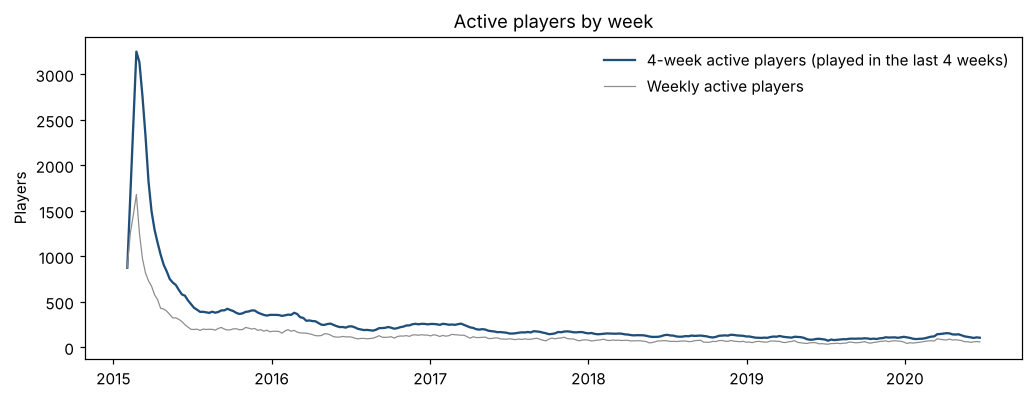

,weeks,avg_weekly_active,avg_active_base,new,reactivated,churned,net_deposits
year,,,,,,,
2015,48,406,835,4376,1452,5471,1537562
2016,52,133,259,244,1287,1635,681866
2017,52,104,191,167,859,1120,909418
2018,53,70,132,91,658,788,938345
2019,52,56,101,63,495,562,796697
2020,25,69,121,57,256,323,351735


In [3]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(kpis.week_start, kpis.active_base, color=NAVY, label="4-week active players (played in the last 4 weeks)")
ax.plot(kpis.week_start, kpis.weekly_active, color=GREY, linewidth=0.8, label="Weekly active players")
ax.set_title("Active players by week")
ax.set_ylabel("Players"); ax.legend(frameon=False)
yearly = kpis.groupby("year").agg(
    weeks=("week_start", "count"),
    avg_weekly_active=("weekly_active", "mean"),
    avg_active_base=("active_base", "mean"),
    new=("new_players", "sum"),
    reactivated=("reactivated", "sum"),
    churned=("churned", "sum"),
    net_deposits=("net_deposits", "sum"),
).round(0).astype(int)
yearly

The cohort follows the classic acquisition curve: the number of 4-week active players peaks in the fourth week at about 3,250 and loses over 80% within six months. After 2016 the decline is slow, which means the players left are a loyal core.

"New" players keep appearing after 2015 because the account was opened in February 2015 for any Entain product, and some players only tried poker months or years later. That is cross-sell from other products, and it is still a source of growth.

Many lost players come back. Across the period there were 5,007 returns against 9,899 losses, so roughly one lost player in two later returned. Win-back campaigns have a real audience.

## 3. Growth and loss each week

Green bars are players gained (new plus returning), red bars are players lost (no play for 4 weeks in a row). The first four months are dominated by onboarding, so this chart starts in June 2015.

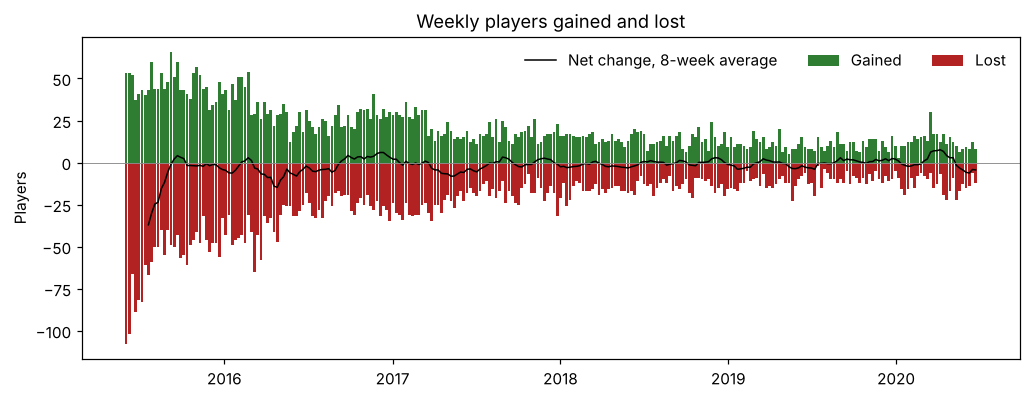

,count,mean,std,min,25%,50%,75%,max
net_change,265.0,-2.2,10.4,-55.0,-6.0,-2.0,4.0,24.0


In [4]:
steady = kpis[kpis.week_start >= "2015-06-01"]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(steady.week_start, steady.new_players + steady.reactivated, width=6, color=GREEN, label="Gained")
ax.bar(steady.week_start, -steady.churned, width=6, color=RED, label="Lost")
ax.plot(steady.week_start, steady.net_change.rolling(8).mean(), color="black", linewidth=1, label="Net change, 8-week average")
ax.axhline(0, color=GREY, linewidth=0.6)
ax.set_title("Weekly players gained and lost")
ax.set_ylabel("Players"); ax.legend(frameon=False, ncol=3)
steady[["net_change"]].describe().T.round(1)

## 4. Player money each week

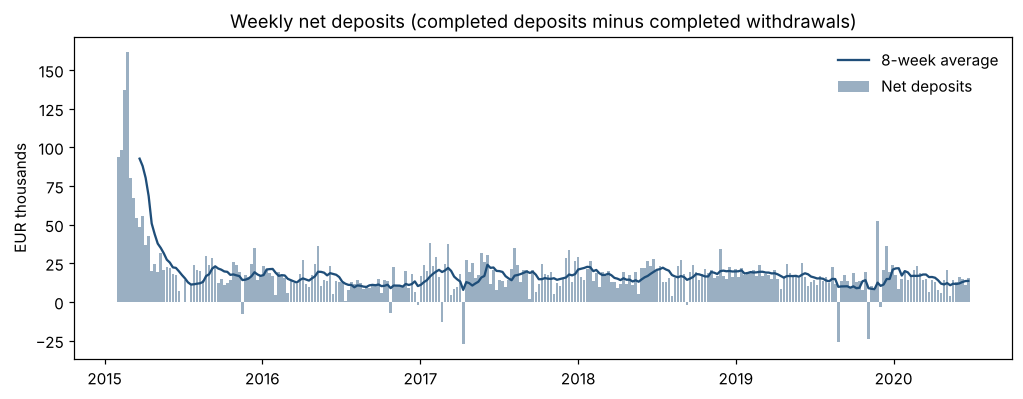

,mean,50%,min,max
deposits,33986.701,29712.690,13554.100,214399.880
withdrawals,15491.579,12739.785,1833.870,65517.910
net_deposits,18495.122,16622.395,-27370.620,161903.830
deposit_failure_rate,0.229,0.220,0.116,0.376


In [5]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(kpis.week_start, kpis.net_deposits / 1000, width=6, color=NAVY, alpha=0.45, label="Net deposits")
ax.plot(kpis.week_start, kpis.net_deposits.rolling(8).mean() / 1000, color=NAVY, label="8-week average")
ax.set_title("Weekly net deposits (completed deposits minus completed withdrawals)")
ax.set_ylabel("EUR thousands"); ax.legend(frameon=False)
kpis[["deposits", "withdrawals", "net_deposits", "deposit_failure_rate"]].describe().T[["mean", "50%", "min", "max"]].round(3)

## 5. The weekly leadership summary

Leadership needs one small table and two sentences. `weekly_summary()` compares any week with the week before and with the average of the previous 8 weeks, and writes the headline automatically.

In [6]:
SUMMARY_METRICS = {
    "weekly_active": "Weekly active players",
    "active_base": "4-week active players",
    "new_players": "New players",
    "reactivated": "Returning players",
    "churned": "Lost players",
    "deposits": "Deposits (EUR)",
    "net_deposits": "Net deposits (EUR)",
    "deposit_failure_rate": "Deposit failure rate",
}

def weekly_summary(week):
    week = pd.Timestamp(week)
    i = kpis.index[kpis.week_start == week][0]
    this, prev, trail = kpis.loc[i], kpis.loc[i - 1], kpis.loc[i - 8:i - 1]
    rows = []
    for col, label in SUMMARY_METRICS.items():
        avg = trail[col].mean()
        rows.append({"metric": label, "this_week": this[col], "last_week": prev[col],
                     "vs_last_week": (this[col] - prev[col]) / prev[col] if prev[col] else None,
                     "8_week_avg": avg, "vs_8_week_avg": (this[col] - avg) / avg if avg else None})
    table = pd.DataFrame(rows).set_index("metric")
    wap, nd = table.loc["Weekly active players"], table.loc["Net deposits (EUR)"]
    headline = (f"Week of {week:%b %d, %Y}: {int(this.weekly_active)} players were active, "
                f"{wap.vs_8_week_avg:+.0%} versus the previous 8-week average, with {int(this.new_players + this.reactivated)} gained "
                f"and {int(this.churned)} lost. Net deposits were EUR {this.net_deposits:,.0f}, "
                f"{nd.vs_8_week_avg:+.0%} versus the previous 8-week average.")
    fmt = table.copy()
    for c in ["this_week", "last_week", "8_week_avg"]:
        fmt[c] = [f"{v:.1%}" if m == "Deposit failure rate" else f"{v:,.0f}" for m, v in fmt[c].items()]
    for c in ["vs_last_week", "vs_8_week_avg"]:
        fmt[c] = fmt[c].map(lambda v: "" if pd.isna(v) else f"{v:+.0%}")
    return headline, fmt

headline, table = weekly_summary("2020-06-22")
print(headline)
table

Week of Jun 22, 2020: 61 players were active, -10% versus the previous 8-week average, with 8 gained and 12 lost. Net deposits were EUR 15,339, +14% versus the previous 8-week average.


,this_week,last_week,vs_last_week,8_week_avg,vs_8_week_avg
metric,,,,,
Weekly active players,61,64,-5%,68,-10%
4-week active players,106,110,-4%,122,-13%
New players,0,2,-100%,2,-100%
Returning players,8,10,-20%,8,-4%
Lost players,12,6,+100%,14,-15%
Deposits (EUR),"20,418","22,007",-7%,"21,882",-7%
Net deposits (EUR),"15,339","10,828",+42%,"13,454",+14%
Deposit failure rate,21.9%,15.4%,+42%,20.3%,+8%


### Example: the first COVID-19 lockdown week

Most of Europe locked down in mid-March 2020. The same function shows what that looked like in the numbers.

In [7]:
headline, table = weekly_summary("2020-03-16")
print(headline)
table

Week of Mar 16, 2020: 95 players were active, +54% versus the previous 8-week average, with 30 gained and 6 lost. Net deposits were EUR 14,634, -17% versus the previous 8-week average.


,this_week,last_week,vs_last_week,8_week_avg,vs_8_week_avg
metric,,,,,
Weekly active players,95,70,+36%,62,+54%
4-week active players,145,121,+20%,103,+41%
New players,4,3,+33%,2,+100%
Returning players,26,10,+160%,12,+126%
Lost players,6,10,-40%,11,-47%
Deposits (EUR),"16,468","24,333",-32%,"27,542",-40%
Net deposits (EUR),"14,634","13,836",+6%,"17,694",-17%
Deposit failure rate,18.9%,20.9%,-10%,17.8%,+6%


Activity jumped well above its average of the previous 8 weeks while net deposits did not rise with it. That gap between engagement and money is the kind of signal to bring to leadership early, and it is investigated in notebook 07 (monitoring).

## Takeaways

1. **Early retention is the biggest lever.** Most of the cohort's losses happen in the first three months, so onboarding and first-month experience matter more than anything later.
2. **Losing a player is often temporary.** About one lost player in two later returned: a win-back program has a real audience.
3. **The base that survives the first year is stable** and keeps depositing for years, which is where lifetime value comes from (notebook 05).

The weekly table is exported to `outputs/weekly_kpis.csv` for the Power BI report.

In [8]:
con.close()